<a href="https://colab.research.google.com/github/sos7549s/-_-_-/blob/main/10%EC%A1%B0_%ED%95%9C%EC%8B%9D%EC%9D%B4%EB%AF%B8%EC%A7%80_%EB%B6%84%EB%A5%98_%EB%94%A5%EB%9F%AC%EB%8B%9D%EB%AF%B8%EB%8B%88%ED%94%84%EB%A1%9C%EC%A0%9D%ED%8A%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==============================================================================
# 10조 딥러닝 미니프로젝트 메인 코랩 (최종 확인용)
# 사용 프레임워크: PyTorch / 구동 환경: Google Colab GPU
# 필독 문서: 교수님 공지 [AI프로젝트 진행 시 필요한 핵심 문서화 요소들.hwpx]
# ==============================================================================

# [공통] 프로젝트 통제 변수
# - 입력 이미지 크기: 224 × 224 (ResNet 표준 입력)
# - 데이터 분할 비율: Train 8 : Validation 1 : Test 1 (Stratified Split)
# - 배치 크기 (Batch Size): 32
# - 에폭 (Epochs): 15 ~ 20
# - 손실 함수 (Loss Function): CrossEntropyLoss
# - 평가지표 (Metrics): Validation Loss, Top-1 Accuracy, Confusion Matrix


In [ ]:
# 1. 최종적으로 빌드된 코드만 합치는 공간입니다. 개인적인 실험이나 테스트 코드는
#    본인의 개인 코랩 사본에서 먼저 돌려본 뒤, 성공하면 여기에 추가해 주세요.

# 2. 각자 담당한 파트의 코드 블록(셀)을 생성할 때,
#    맨 위에 # [담당자: 이름]을 주석으로 명시해 주세요. (예: # [데이터] 담당: 김하늘)

# 3. 타인 코드 수정은 최소한으로 해주세요(주석 필수): 다른사람이 작성한 코드 셀을 수정하거나 추가할 경우,
#    기존 코드 #으로 지우되 원본을 지우지 말아주시고, 아래 예시처럼 수정 이유를 주석으로 남겨주세요.
#    [예시: # [수정 - 강승태] OOO 에러 해결을 위해 lr을 0.001로 변경함]

# 4. 전체 실행(Run All) 검증: 코드를 추가한 후에는
#    맨 위 셀부터 맨 아래 셀까지 오류 없이 한 번에 실행되는지 반드시 확인하고 저장해 주세요.

In [ ]:
# ==============================================================================
# 10조 딥러닝 미니프로젝트 메인 파이프라인
# 사용 프레임워크: PyTorch / 구동 환경: Google Colab GPU
# ==============================================================================

# [공통/시각화] 담당: 오주희
# =======================================================================
# Step 1. 환경 설정 및 통합 라이브러리 호출
# =======================================================================
# 한글 폰트 렌더링 세팅 (Colab 환경)
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

from google.colab import drive

# 1. 드라이브 마운트 및 연산 장치 설정
drive.mount('/content/drive', force_remount=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n연산 장치 설정 완료: {device}")

# 2. 한글 폰트 적용 (런타임 재시작 후 정상 작동)
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 51 not upgraded.
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 16 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/root/.local/share/fonts: skipping, no such directory
/root/.fonts: skipping, no such directory
/usr/share/fonts/truetype: skipping, looped directory detected
/usr/share/fonts/truetype/humor-sans: skipping, looped directory detected
/usr/share/fonts/truetype/liberation: skipping, looped directory detected
/usr/share/fonts/truetype/

In [ ]:
# [데이터] 담당: 김하늘
# 이미지 전처리 및 DataLoader 완수 코드

# [1단계] 코랩과 구글 드라이브를 하나로 연결하는 과정입니다.
from google.colab import drive  # 구글 코랩 시스템에서 드라이브 연결 도구를 가져옵니다.
drive.mount('/content/drive')   # 내 구글 드라이브를 코랩 가상 컴퓨터 안에 탑재(마운트)합니다.

# [2단계] 이미지 가공 및 데이터 분할에 필요한 파이썬 필수 라이브러리들을 불러옵니다.
import os                       # 컴퓨터의 폴더 경로 및 파일 시스템을 다루는 라이브러리입니다.
import torch                    # 파이토치(PyTorch) 딥러닝 프레임워크의 메인 핵심 라이브러리입니다.
import numpy as np              # 인덱스 계산 및 행렬 처리를 빠르게 돕는 수학 라이브러리입니다.
from torchvision import datasets, transforms  # 이미지 데이터셋 로드 및 전처리 가공 도구를 가져옵니다.
from torch.utils.data import DataLoader, Subset  # 미니배치 배달 기차와 데이터셋 부분 추출 도구를 가져옵니다.
from sklearn.model_selection import train_test_split  # 데이터를 황금 비율로 쪼개주는 머신러닝 도구를 가져옵니다.


# [3단계] 계획서 지침에 맞춰 학습용 이미지 가공 방식(Resize + Augmentation + 정규화)을 정의합니다.
train_transform = transforms.Compose([  # 아래 적어준 여러 개의 전처리 명령을 차례대로 연쇄 실행하겠다는 선언입니다.
    transforms.Resize((224, 224)),               # 4:3이든 16:9든 상관없이 모든 사진을 224x224 정사각형으로 구겨 넣습니다.
    transforms.RandomHorizontalFlip(p=0.5),      # 데이터 증강(Augmentation): 50%의 확률로 사진을 좌우로 뒤집어 데이터를 뻥튀기합니다.
    transforms.RandomRotation(15),               # 데이터 증강(Augmentation): 사진을 무작위로 15도 내외로 회전시켜 과적합을 방지합니다.
    transforms.ToTensor(),                       # 이미지를 컴퓨터(인공지능)가 계산할 수 있는 0~1 사이의 숫자 행렬(Tensor)로 바꿉니다.
    transforms.Normalize(                        # ResNet-50 사전학습 모델이 원래 공부했던 ImageNet 기준의 색감/밝기로 표준화합니다.
        mean=[0.485, 0.456, 0.406],              # 빨강(R), 초록(G), 파랑(B) 채널별 공식 평균 가이드라인 숫자 세트입니다.
        std=[0.229, 0.224, 0.225]                # 빨강(R), 초록(G), 파랑(B) 채널별 공식 표준편차 가이드라인 숫자 세트입니다.
    )
])


# [4단계] 검증용(Val)과 테스트용(Test) 이미지 가공 방식을 정의합니다. (순수한 시험용이므로 뒤집기/회전 같은 증강은 뺍니다.)
val_test_transform = transforms.Compose([  # 검증 및 테스트 데이터 전용 가공 명령서를 생성합니다.
    transforms.Resize((224, 224)),         # 시험용 사진들도 입력 구멍 크기에 맞춰 똑같이 224x224로 크기를 통일합니다.
    transforms.ToTensor(),                 # 시험용 사진들도 컴퓨터가 읽을 수 있게 숫자 행렬(Tensor)로 변환합니다.
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # 학습용과 완벽히 동등한 기준의 색감 톤 정규화를 적용합니다.
])


# [5단계] 구글 드라이브에 올려둔 내 한식 데이터셋 폴더 경로를 파이썬에게 가리켜줍니다.
data_dir = '/content/drive/MyDrive/KFood_Subset'  # 10개 음식 폴더(각 400장씩 총 4000장)가 들어있는 구글 드라이브 주소입니다.


# [6단계] 계획서 핵심 지침인 [Stratified Split (층화 분할)] 기반의 8:1:1 데이터 분할을 실행합니다.
full_dataset = datasets.ImageFolder(root=data_dir)  # 주소에 있는 폴더명을 정답(라벨)으로 삼아 전체 4,000장 데이터를 일단 통째로 읽어옵니다.
indices = np.arange(len(full_dataset))             # 0번부터 3999번까지 전체 사진에 고유 일련번호(인덱스)를 매깁니다.
labels = full_dataset.targets                      # 각 사진이 어떤 음식(김치찌개, 짜장면 등)인지 정답지 목록만 따로 추출합니다.

# 1차 분할: 전체 4,000장을 학습용(Train 80% = 3,200장)과 잔여 데이터(20% = 800장)로 공정하게 분할합니다.
train_idx, val_test_idx = train_test_split(        # 층화 분할 알고리즘을 사용해 인덱스를 8:2 비율로 무작위로 쪼갭니다.
    indices, test_size=0.2, stratify=labels, random_state=42  # stratify=labels 덕분에 10개 음식이 치우침 없이 똑같은 비율로 쪼개집니다.
)

# 2차 분할: 남은 20%(800장)를 검증용(Val 10% = 400장)과 최종 테스트용 (Test 10% = 400장)으로 정확히 반반씩 칼더치합니다.
val_test_labels = [labels[i] for i in val_test_idx]  # 남은 800장 사진의 음식 정답 목록을 다시 한번 체크합니다.
val_idx, test_idx = train_test_split(              # 남은 800장을 다시 5:5 비율로 쪼개어 최종 400장씩 나눕니다.
    val_test_idx,
    test_size=0.5,
    stratify=val_test_labels,  # 층화 분할 유지
    random_state=42            # 언제 어디서 실행해도 동일한 분할 결과가 나오도록 랜덤 시드를 고정합니다.
)

# 3차 매핑: 쪼개진 일련번호 묶음마다 위에서 설계한 Transform을 각각 알맞게 매칭시켜 줍니다.
train_dataset = Subset(datasets.ImageFolder(root=data_dir, transform=train_transform), train_idx)  # 학습 데이터엔 리사이즈+데이터증강+정규화를 바인딩합니다.
val_dataset = Subset(datasets.ImageFolder(root=data_dir, transform=val_test_transform), val_idx)    # 검증 데이터엔 증강을 제외한 순수 규격 가공만 바인딩합니다.
test_dataset = Subset(datasets.ImageFolder(root=data_dir, transform=val_test_transform), test_idx)  # 테스트 데이터에도 순수 규격 가공만 깔끔하게 바인딩합니다.


# [7단계] 계획서 하이퍼파라미터 지침에 맞게 [배치 크기 32] 설정 후 DataLoader 기차를 최종 완수합니다.
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)   # 학습용 기차: 32장씩 묶어서, 순서를 무작위로 섞어서 배달합니다.
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)     # 검증용 기차: 32장씩 묶어서, 정해진순서 그대로 정직하게 배달합니다.
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)   # 테스트 기차: 32장씩 묶어서, 원본 순서 그대로 안전하게 배달합니다.


# [8단계] 작업이 완벽하게 끝났음을 화면에 출력하여 인증합니다.
print("전처리 및 데이터로더 최종 구현 완료")
print(f"-> 학습용(Train) 데이터 기차: {len(train_dataset)}장 세팅 (배치크기 32)")
print(f"-> 검증용(Val) 데이터 기차: {len(val_dataset)}장 세팅")
print(f"-> 테스트용(Test) 데이터 기차: {len(test_dataset)}장 세팅")

# 이 밑부터 코드 작성 하시면 됩니다

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
전처리 및 데이터로더 최종 구현 완료
-> 학습용(Train) 데이터 기차: 3200장 세팅 (배치크기 32)
-> 검증용(Val) 데이터 기차: 400장 세팅
-> 테스트용(Test) 데이터 기차: 400장 세팅


In [ ]:
# [시각화] 담당: 오주희 (데이터 확인용)
#정상 결과 예시: tensor([3, 1, 7, 0, 2, 9, 4, ...])처럼 숫자가 섞여 나와야 합니다.
#비정상 결과: 여전히 0만 나온다면 데이터 폴더 자체의 로드 문제입니다.

# 검증 로더에서 1개 배치(32장)만 뽑아서 라벨 확인
images, labels = next(iter(val_loader))
print(labels)

tensor([2, 5, 7, 5, 4, 4, 0, 3, 1, 7, 8, 8, 4, 6, 0, 8, 1, 7, 9, 4, 5, 3, 6, 1,
        5, 9, 9, 9, 4, 5, 8, 2])


In [ ]:
# [데이터] 담당: 김하늘 (추가)
# [1단계] 요청사항을 반영한 고급 데이터 증강(Advanced Transform) 정의
train_transform_advanced = transforms.Compose([
    transforms.Resize((224, 224)),               # 기본 224x224 리사이즈 유지
    transforms.RandomHorizontalFlip(p=0.5),      # 기본 좌우 반전 유지
    transforms.RandomRotation(15),               # 기본 15도 회전 유지

    # 1. ColorJitter: 밝기(brightness), 대비(contrast), 채도(saturation)를 20% 내외로 무작위 변형
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),

    # 2. RandomResizedCrop: 이미지의 80%~100% 영역을 무작위로 잘라내어(Crop) 다시 224x224로 확대
    #    -> 음식의 국물 색상, 질감 등 세부 특징(Feature) 학습 유도
    transforms.RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0)),

    # 3. RandomVerticalFlip: 상하 반전 추가 (현실성 없는 과도한 증강으로 인한 성능 저하 증명용)
    transforms.RandomVerticalFlip(p=0.5),


    transforms.ToTensor(),                       # 컴퓨터용 숫자로 변환
    transforms.Normalize(                        # ImageNet 표준 정규화 적용
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# [2단계] 고급 증강 조리법을 기존의 학습용 인덱스(train_idx)에 그대로 매핑하여 가상 데이터셋 구축
# (※ 이미 8:1:1로 쪼개놓은 train_idx를 그대로 쓰기 때문에 데이터 오염이나 치우침이 전혀 없습니다.)
train_dataset_advanced = Subset(
    datasets.ImageFolder(root=data_dir, transform=train_transform_advanced),
    train_idx
)


# [3단계] 통제 변수 지침에 맞게 [배치 크기 32] 설정 후 고급 데이터로더(train_loader_advanced) 완수
train_loader_advanced = DataLoader(train_dataset_advanced, batch_size=32, shuffle=True)


# [4단계] 고급 실험셋 구축 완료 메시지 출력

print(f"-> 고급 학습용(Train Advanced) 데이터: {len(train_dataset_advanced)}장 세팅 완료")

# 나중에 성능 비교 실험할 때 원래 train_loader 대신에 train_loader_advanced 넣어서 돌려보고 결과 비교하면 됩니다

-> 고급 학습용(Train Advanced) 데이터: 3200장 세팅 완료


In [ ]:
#[모델링] 담당: 강승태

# =======================================================================
# [1단계] 개발 환경 설정 및 구글 드라이브 마운트
# =======================================================================
from google.colab import drive
drive.mount('/content/drive')

import os
import pickle
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
import torchvision.models as models

# 연산 장치(GPU) 활성화 확인
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n연산 장치 설정 완료 (Device): {device}")


# =======================================================================
# [2단계] 데이터 전처리 규격 및 층화 분할(Stratified Split) 정의
# =======================================================================
# 1) 학습용 데이터 전처리 (리사이즈 + 기본 데이터 증강 + ImageNet 표준 정규화)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2) 검증 및 테스트용 데이터 전처리 (순수 규격 맞춤 및 정규화만 적용)
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3) 구글 드라이브 원본 데이터셋 경로 지정
data_dir = '/content/drive/MyDrive/KFood_Subset'

# 4) 데이터 읽기 및 8:1:1 층화 분할 알고리즘 가동 (데이터 누수 차단)
full_dataset = datasets.ImageFolder(root=data_dir)
indices = np.arange(len(full_dataset))
labels = full_dataset.targets

# 1차 분할: 학습 데이터(80%)와 나머지(20%) 분할
train_idx, val_test_idx = train_test_split(
    indices, test_size=0.2, stratify=labels, random_state=42
)

# 2차 분할: 남은 20%를 검증(10%)과 테스트(10%)로 정확히 배분
val_test_labels = [labels[i] for i in val_test_idx]
val_idx, test_idx = train_test_split(
    val_test_idx, test_size=0.5, stratify=val_test_labels, random_state=42
)


# 5) 쪼개진 인덱스별로 전처리 조리법(Transform) 매핑
train_dataset = Subset(datasets.ImageFolder(root=data_dir, transform=train_transform), train_idx)
val_dataset = Subset(datasets.ImageFolder(root=data_dir, transform=val_test_transform), val_idx)
test_dataset = Subset(datasets.ImageFolder(root=data_dir, transform=val_test_transform), test_idx)


# =======================================================================
# [3단계] 배치 설정 및 DataLoader 구축 (+ 구글 드라이브 병목 가속화)
# =======================================================================
# 💡 num_workers=2와 pin_memory=True를 주입하여 드라이브 입출력 병목과 렉을 방지합니다.
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print("\n📊 [데이터 인프라 연동 완료]")
print(f"-> 학습용(Train) 데이터: {len(train_dataset)}장 세팅 (배치크기 32)")
print(f"-> 검증용(Val) 데이터: {len(val_dataset)}장 세팅")
print(f"-> 테스트용(Test) 데이터: {len(test_dataset)}장 세팅")


# =======================================================================
# [추가 옵션] 하늘님의 고급 데이터 증강(Advanced Transform) 파이프라인
# =======================================================================
train_transform_advanced = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0)),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset_advanced = Subset(datasets.ImageFolder(root=data_dir, transform=train_transform_advanced), train_idx)
train_loader_advanced = DataLoader(train_dataset_advanced, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
print(f"-> 고급 학습용(Train Advanced) 데이터: {len(train_dataset_advanced)}장 세팅 완료\n")


# =======================================================================
# [4단계] 실험 조건별 모델 초기화 및 가중치 제어 함수
# =======================================================================
def initialize_resnet50(num_classes=10, experiment_case="Case1"):
    """
    Case 1: 사전학습 가중치 사용 + 백본 레이어 동결 (특성 추출)
    Case 2: 사전학습 가중치 사용 + 전체 레이어 개방 (미세 조정)
    Case 3: 무작위 가중치 초기화(weights=None) + 전체 레이어 개방 (Scratch 학습)
    """
    if experiment_case == "Case3":
        model = models.resnet50(weights=None)
        print(f"[{experiment_case}] 모델 초기화 유형: 텅 빈 가중치 모델(Scratch) 생성 완료")
    else:
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        print(f"[{experiment_case}] 모델 초기화 유형: 사전 학습된 가중치(Pretrained) 로드 완료")

    if experiment_case == "Case1":
        for param in model.parameters():
            param.requires_grad = False
    elif experiment_case == "Case2" or experiment_case == "Case3":
        for param in model.parameters():
            param.requires_grad = True

    # 최종 출력 레이어 재구성
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)

    for param in model.fc.parameters():
        param.requires_grad = True

    return model.to(device)

'''
# =======================================================================
# [5단계] 단일 실험 학습 및 검증 코어 루프 함수 (인자 명칭 에러 완벽 해결)
# =======================================================================
def run_experiment(case_name, train_loader, val_loader, num_classes=10, num_epochs=10):
    """
    케이스별 동적 학습률을 적용하고 최종 에포크의 예측값과 정답 배열을 반환하는 함수
    """
    # 피드백 반영: Case 2 가중치 파괴 방지를 위한 동적 학습률 제어
    if case_name == "Case2":
        learning_rate = 0.0001  # 1e-4
    else:
        learning_rate = 0.001   # 1e-3

    print(f"\n==========================================")
    print(f"🚀 {case_name} 실험 가동 (Epochs: {num_epochs} | 설정된 LR: {learning_rate})")
    print(f"==========================================")

    model = initialize_resnet50(num_classes=num_classes, experiment_case=case_name)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=learning_rate)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    final_preds = []
    final_targets = []

    for epoch in range(num_epochs):
        # --- ① 훈련(Train) 루프 ---
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0

        for batch_idx, (inputs, targets) in enumerate(train_loader):
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            train_correct += torch.sum(preds == targets.data)
            train_total += inputs.size(0)

            if batch_idx % 5 == 0:
                print(".", end="", flush=True)

        epoch_train_loss = train_loss / train_total
        epoch_train_acc = (train_correct.double() / train_total) * 100

        # --- ② 검증(Validation) 루프 ---
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        epoch_preds = []
        epoch_targets = []

        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)

                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += torch.sum(preds == targets.data)
                val_total += inputs.size(0)

                # 시각화 및 혼동행렬용 예측값/정답 누적
                epoch_preds.extend(preds.cpu().tolist())
                epoch_targets.extend(targets.cpu().tolist())

        epoch_val_loss = val_loss / val_total
        epoch_val_acc = (val_correct.double() / val_total) * 100

        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc.item())
        history["val_loss"].append(epoch_val_loss)
        history["val_acc"].append(epoch_val_acc.item())

        # 마지막 에포크의 데이터 바인딩
        if epoch == num_epochs - 1:
            final_preds = epoch_preds
            final_targets = epoch_targets

        print(f"\nEpoch [{epoch+1}/{num_epochs}]")
        print(f"  [Train] Loss: {epoch_train_loss:.4f} | Accuracy: {epoch_train_acc:.2f}%")
        print(f"  [Validation] Loss: {epoch_val_loss:.4f} | Accuracy: {epoch_val_acc:.2f}%")

    print(f"✨ {case_name} 실험 프로세스 완료.")
    return history, final_preds, final_targets


# =======================================================================
# [6 & 7단계 통합] 기본 vs 고급 증강 데이터셋 순차 대조 실험 및 자동 내보내기(Export)
# =======================================================================

# 실험을 수행할 공통 케이스 세팅
cases_to_run = ["Case1", "Case2", "Case3"]
target_num_classes = len(full_dataset.classes)
drive_save_dir = "/content/drive/MyDrive"

# -----------------------------------------------------------------------
# PART 1: 기본 데이터 실험 파트 (train_loader 주입)
# -----------------------------------------------------------------------
print("\n=======================================================================")
print("📢 [PART 1] 기본 데이터셋(Baseline Dataset) 대조 실험 가동")
print("=======================================================================")

all_results_basic = {}

for case in cases_to_run:
    # 💡 기본 train_loader 주입
    history, all_preds, all_targets = run_experiment(
        case_name=case,
        train_loader=train_loader,
        val_loader=val_loader,
        num_classes=target_num_classes,
        num_epochs=10,
    )

    all_results_basic[case] = {
        "history": history,
        "all_preds": all_preds,
        "all_targets": all_targets,
    }

# [PART 1 결과 Export] all_results_basic.pkl 저장
basic_save_path = os.path.join(drive_save_dir, "all_results_basic.pkl")
try:
    with open(basic_save_path, "wb") as f:
        pickle.dump(all_results_basic, f)
    print(f"\n💾 [Export 완료] 기본 데이터 실험 결과 ➡️ {basic_save_path}\n")
except Exception as e:
    with open("all_results_basic.pkl", "wb") as f:
        pickle.dump(all_results_basic, f)
    print(f"\n⚠️ 구글 드라이브 접근 제한으로 로컬 세션에 백업 ➡️ all_results_basic.pkl\n")


# -----------------------------------------------------------------------
# PART 2: 고급 증강 데이터 실험 파트 (train_loader_advanced 주입)
# -----------------------------------------------------------------------
print("\n=======================================================================")
print("📢 [PART 2] 고급 증강 데이터셋(Advanced Augmentation) 대조 실험 가동")
print("=======================================================================")

all_results_advanced = {}

for case in cases_to_run:
    # 💡 하늘님이 빌드한 고급 증강 train_loader_advanced 주입 (검증 로더는 오염 방지를 위해 기존 val_loader 유지)
    history, all_preds, all_targets = run_experiment(
        case_name=case,
        train_loader=train_loader_advanced,
        val_loader=val_loader,
        num_classes=target_num_classes,
        num_epochs=10,
    )

    all_results_advanced[case] = {
        "history": history,
        "all_preds": all_preds,
        "all_targets": all_targets,
    }

# [PART 2 결과 Export] all_results_advanced.pkl 저장
advanced_save_path = os.path.join(drive_save_dir, "all_results_advanced.pkl")
try:
    with open(advanced_save_path, "wb") as f:
        pickle.dump(all_results_advanced, f)
    print(f"\n💾 [Export 완료] 증강 데이터 실험 결과 ➡️ {advanced_save_path}\n")
except Exception as e:
    with open("all_results_advanced.pkl", "wb") as f:
        pickle.dump(all_results_advanced, f)
    print(f"\n⚠️ 구글 드라이브 접근 제한으로 로컬 세션에 백업 ➡️ all_results_advanced.pkl\n")


print("\n=======================================================================")
print("🎉 [실험 종료] 기본/증강 데이터셋 순차 대조 파이프라인이 완전 종료되었습니다.")
print("💾 구글 드라이브에 'all_results_basic.pkl'과 'all_results_advanced.pkl'이 생성되었습니다.")
print("=======================================================================")
'''
# [시각화] 담당: 오주희, test 성능이 필요해 코드 수정후 추가
# =======================================================================
# [5단계 수정본] 단일 실험 학습 및 검증 코어 루프 함수 (★최종 테스트 평가 추가)
# =======================================================================
def run_experiment(case_name, train_loader, val_loader, test_loader, num_classes=10, num_epochs=10):
    if case_name == "Case2":
        learning_rate = 0.0001
    else:
        learning_rate = 0.001

    print(f"\n==========================================")
    print(f" {case_name} 실험 가동 (Epochs: {num_epochs} | 설정된 LR: {learning_rate})")
    print(f"==========================================")

    model = initialize_resnet50(num_classes=num_classes, experiment_case=case_name)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=learning_rate)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    # [1] 에포크 반복 (Train & Validation)
    for epoch in range(num_epochs):
        # --- ① 훈련(Train) 루프 ---
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0

        for batch_idx, (inputs, targets) in enumerate(train_loader):
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            train_correct += torch.sum(preds == targets.data)
            train_total += inputs.size(0)

            if batch_idx % 5 == 0:
                print(".", end="", flush=True)

        epoch_train_loss = train_loss / train_total
        epoch_train_acc = (train_correct.double() / train_total) * 100

        # --- ② 검증(Validation) 루프 ---
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)

                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += torch.sum(preds == targets.data)
                val_total += inputs.size(0)

        epoch_val_loss = val_loss / val_total
        epoch_val_acc = (val_correct.double() / val_total) * 100

        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc.item())
        history["val_loss"].append(epoch_val_loss)
        history["val_acc"].append(epoch_val_acc.item())

        print(f"\nEpoch [{epoch+1}/{num_epochs}]")
        print(f"  [Train] Loss: {epoch_train_loss:.4f} | Accuracy: {epoch_train_acc:.2f}%")
        print(f"  [Validation] Loss: {epoch_val_loss:.4f} | Accuracy: {epoch_val_acc:.2f}%")

    # ---------------------------------------------------------
    # 🎯 [2] 추가된 파트: 학습 종료 후, 최종 테스트(Test) 셋으로 '진짜 수능 시험' 가동!
    # ---------------------------------------------------------
    print(f"\\[최종 평가] 미지의 테스트 데이터(Test Set)로 수능 시험 가동 중...")
    model.eval()
    test_loss, test_correct, test_total = 0.0, 0, 0
    test_preds = []
    test_targets = []

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            test_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            test_correct += torch.sum(preds == targets.data)
            test_total += inputs.size(0)

            # 💡 기존 val 데이터가 아닌, 진짜 'test 데이터'의 예측값과 정답을 수집합니다.
            test_preds.extend(preds.cpu().tolist())
            test_targets.extend(targets.cpu().tolist())

    final_test_loss = test_loss / test_total
    final_test_acc = (test_correct.double() / test_total) * 100

    print(f" 🏆 [최종 Test 성적] Loss: {final_test_loss:.4f} | Accuracy: {final_test_acc:.2f}%\n")

    # 모델의 뇌(가중치)를 물리적으로 백업 저장 (이후 재학습 방지)
    save_path = f"/content/drive/MyDrive/Model_{case_name}.pth"
    torch.save(model.state_dict(), save_path)
    print(f" 💾 모델 가중치 백업 완료: {save_path}")

    print(f"✨ {case_name} 실험 프로세스 완료.")

    # 💡 반환값 변경: val 예측값이 아닌, 진짜 수능 성적인 test_preds를 반환!
    return history, test_preds, test_targets


# =======================================================================
# [6 & 7단계 통합 수정본] 시간 33% 단축! 보고서용 핵심 4개 케이스만 최적화 실행
# =======================================================================

target_num_classes = len(full_dataset.classes)
drive_save_dir = "/content/drive/MyDrive"

# -----------------------------------------------------------------------
# PART 1: 기본 데이터 실험 파트 (Case 1, 2, 3 전체 비교)
# -----------------------------------------------------------------------
print("\n=======================================================================")
print("📢 [PART 1] 기본 데이터셋 대조 실험 가동 (Case 1, 2, 3)")
print("=======================================================================")

all_results_test_basic = {}
cases_to_run_basic = ["Case1", "Case2", "Case3"]

for case in cases_to_run_basic:
    history, test_preds, test_targets = run_experiment(
        case_name=case,
        train_loader=train_loader,
        val_loader=val_loader,
        test_loader=test_loader,  # 💡 드디어 테스트 로더 주입!
        num_classes=target_num_classes,
        num_epochs=10,
    )

    all_results_test_basic[case] = {
        "history": history,
        "test_preds": test_preds,      # 검증용이 아닌 '테스트용' 예측값 저장
        "test_targets": test_targets   # 검증용이 아닌 '테스트용' 정답 저장
    }

basic_save_path = os.path.join(drive_save_dir, "test_results_basic.pkl")
with open(basic_save_path, "wb") as f:
    pickle.dump(all_results_test_basic, f)
print(f"\n💾 [Export 완료] 기본 데이터(Test) 결과 ➡️ {basic_save_path}\n")


# -----------------------------------------------------------------------
# PART 2: 고급 증강 데이터 실험 파트 (시간 절약을 위해 'Case 4'만 단독 실행)
# -----------------------------------------------------------------------
print("\n=======================================================================")
print("📢 [PART 2] 고급 증강 데이터 대조 실험 가동 (보고서의 Case 4)")
print("=======================================================================")

all_results_test_advanced = {}
# 💡 시간을 아끼기 위해 쓸데없는 Case 1, 3은 빼고 최고 성능인 'Case 2' 조건만 단독 실행!
history, test_preds, test_targets = run_experiment(
    case_name="Case2",
    train_loader=train_loader_advanced,  # 하늘님의 고급 증강 데이터 주입
    val_loader=val_loader,
    test_loader=test_loader,
    num_classes=target_num_classes,
    num_epochs=10,
)

# 저장할 때는 헷갈리지 않게 'Case4' 라는 이름으로 명명
all_results_test_advanced["Case4"] = {
    "history": history,
    "test_preds": test_preds,
    "test_targets": test_targets
}

advanced_save_path = os.path.join(drive_save_dir, "test_results_advanced.pkl")
with open(advanced_save_path, "wb") as f:
    pickle.dump(all_results_test_advanced, f)
print(f"\n💾 [Export 완료] 증강 데이터(Test) 결과  {advanced_save_path}\n")

print("\n 모든 테스트(Test) 평가 및 저장이 완벽하게 종료되었습니다!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

연산 장치 설정 완료 (Device): cuda

📊 [데이터 인프라 연동 완료]
-> 학습용(Train) 데이터: 3200장 세팅 (배치크기 32)
-> 검증용(Val) 데이터: 400장 세팅
-> 테스트용(Test) 데이터: 400장 세팅
-> 고급 학습용(Train Advanced) 데이터: 3200장 세팅 완료


📢 [PART 1] 기본 데이터셋 대조 실험 가동 (Case 1, 2, 3)

 Case1 실험 가동 (Epochs: 10 | 설정된 LR: 0.001)
[Case1] 모델 초기화 유형: 사전 학습된 가중치(Pretrained) 로드 완료
........

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


............

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Epoch [1/10]
  [Train] Loss: 1.4833 | Accuracy: 65.78%
  [Validation] Loss: 0.9338 | Accuracy: 80.00%
.......

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


... (151 outputs left out)

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...........

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Epoch [10/10]
  [Train] Loss: 0.0552 | Accuracy: 98.47%
  [Validation] Loss: 0.2289 | Accuracy: 93.00%
\[최종 평가] 미지의 테스트 데이터(Test Set)로 수능 시험 가동 중...
 🏆 [최종 Test 성적] Loss: 0.2465 | Accuracy: 93.25%

 💾 모델 가중치 백업 완료: /content/drive/MyDrive/Model_Case2.pth
✨ Case2 실험 프로세스 완료.

💾 [Export 완료] 증강 데이터(Test) 결과  /content/drive/MyDrive/test_results_advanced.pkl


 모든 테스트(Test) 평가 및 저장이 완벽하게 종료되었습니다!


In [ ]:
# [시각화] 담당: 오주희
#한글 폰트 설치 (새 코드 셀 생성 후 실행)
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 51 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 0s (22.4 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 122402 files and direc

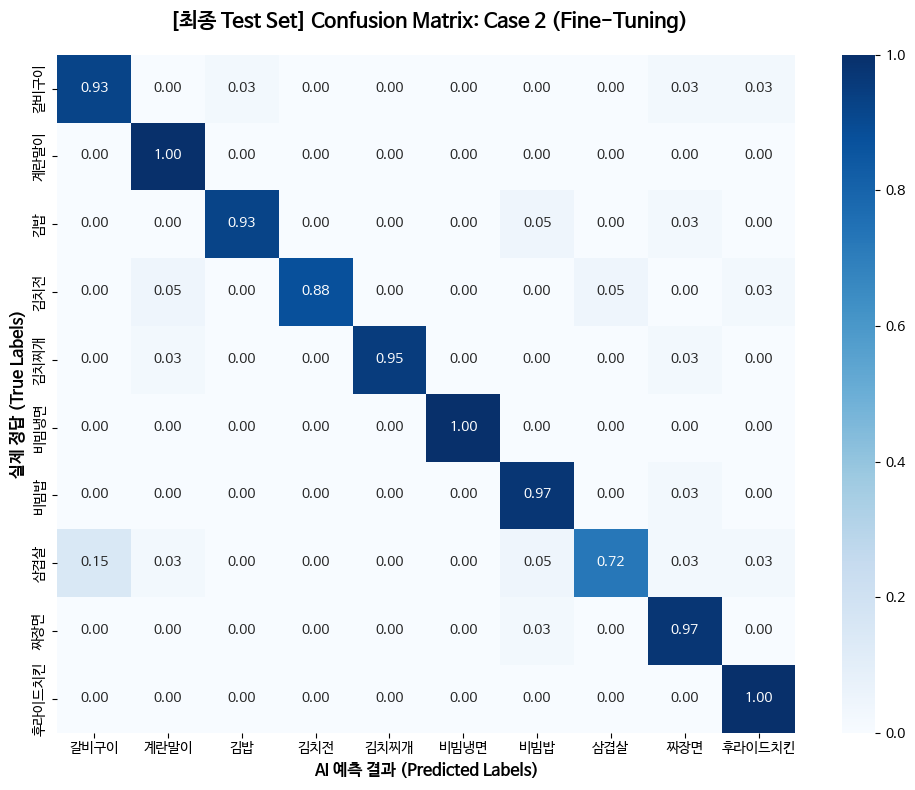


 [최종 성적] Case 2: 클래스별 세부 평가지표 (Test Set 기준)
              precision    recall  f1-score   support

        갈비구이       0.86      0.93      0.89        40
        계란말이       0.91      1.00      0.95        40
          김밥       0.97      0.93      0.95        40
         김치전       1.00      0.88      0.93        40
        김치찌개       1.00      0.95      0.97        40
        비빔냉면       1.00      1.00      1.00        40
         비빔밥       0.89      0.97      0.93        40
         삼겹살       0.94      0.72      0.82        40
         짜장면       0.89      0.97      0.93        40
      후라이드치킨       0.93      1.00      0.96        40

    accuracy                           0.94       400
   macro avg       0.94      0.93      0.93       400
weighted avg       0.94      0.94      0.93       400



In [ ]:
# [시각화] 담당: 오주희
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# [사전 준비] 한글 폰트 세팅 (런타임 다시 시작 후 실행 필수)
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

# -----------------------------------------------------------------------
# 1. '진짜 수능 성적'이 담긴 새로운 테스트 피클 파일 로드
# -----------------------------------------------------------------------
# 💡 주의: basic 파일이 아니라 새로 생성된 'test_results_basic.pkl' 입니다!
with open('/content/drive/MyDrive/test_results_basic.pkl', 'rb') as f:
    test_results = pickle.load(f)

# 2. 가장 똑똑했던 Case 2의 'Test 데이터' 예측값과 정답지 추출
# (키 값이 val_preds에서 test_preds로 변경되었습니다)
preds = test_results['Case2']['test_preds']
targets = test_results['Case2']['test_targets']

# 클래스 이름 정의 (원본 데이터셋 폴더 순서와 동일하게 매핑)
class_names = ['갈비구이', '계란말이', '김밥', '김치전', '김치찌개',
               '비빔냉면', '비빔밥', '삼겹살', '짜장면', '후라이드치킨']

# -----------------------------------------------------------------------
# 3. 정규화(Normalized)된 Confusion Matrix 시각화
# -----------------------------------------------------------------------
# normalize='true'를 넣어 0.0 ~ 1.0 사이의 비율(Percentage)로 변환
cm_normalized = confusion_matrix(targets, preds, normalize='true')

plt.figure(figsize=(10, 8))
# fmt='.2f'로 소수점 둘째 자리까지 출력하여 가독성 확보
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

# 제목에 명확하게 'Test Set' 임을 명시!
plt.title(' [최종 Test Set] Confusion Matrix: Case 2 (Fine-Tuning)', fontsize=15, fontweight='bold', pad=20)
plt.xlabel('AI 예측 결과 (Predicted Labels)', fontsize=12, fontweight='bold')
plt.ylabel('실제 정답 (True Labels)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------
# 4. 세부 평가지표 (Classification Report) 출력
# -----------------------------------------------------------------------
print("\n" + "="*70)
print(" [최종 성적] Case 2: 클래스별 세부 평가지표 (Test Set 기준)")
print("="*70)
# 보고서 테이블에 그대로 복사해 넣기 좋도록 출력
report = classification_report(targets, preds, target_names=class_names)
print(report)
print("="*70)

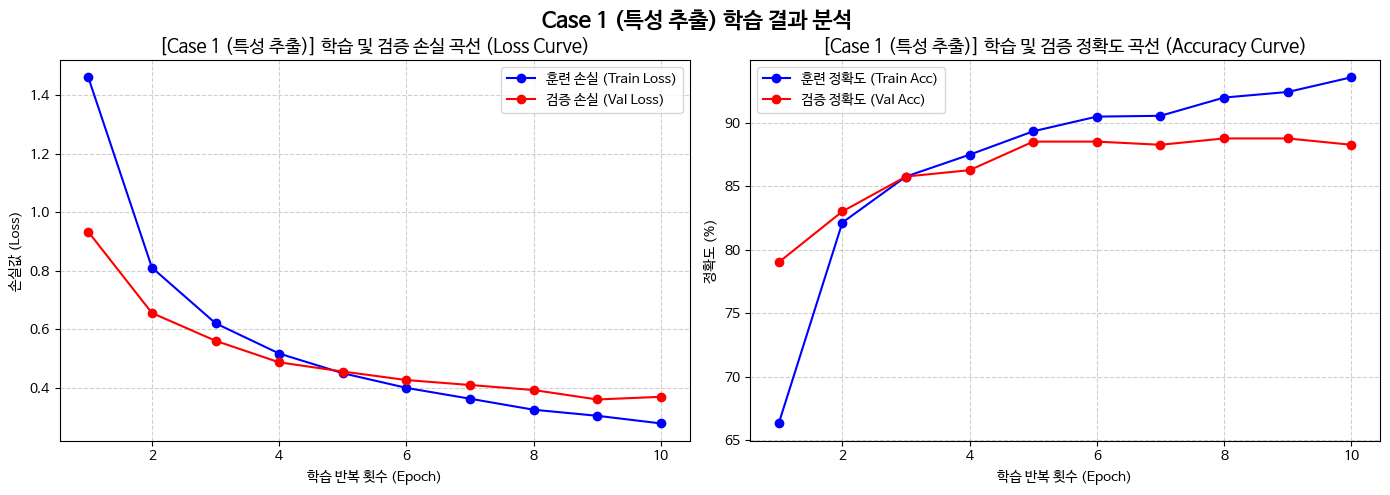

--------------------------------------------------------------------------------


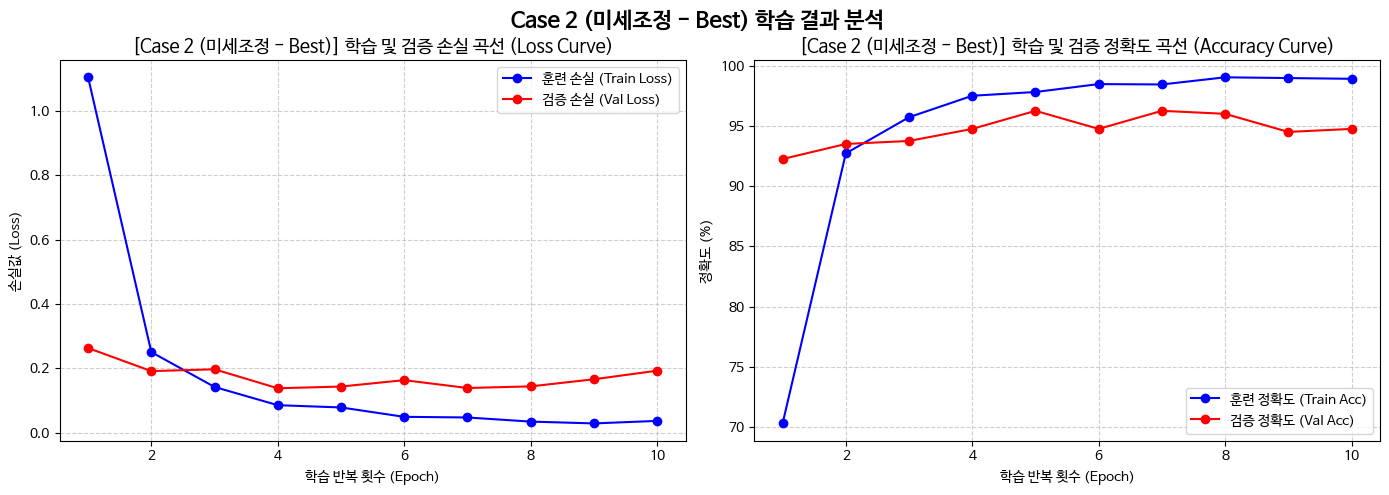

--------------------------------------------------------------------------------


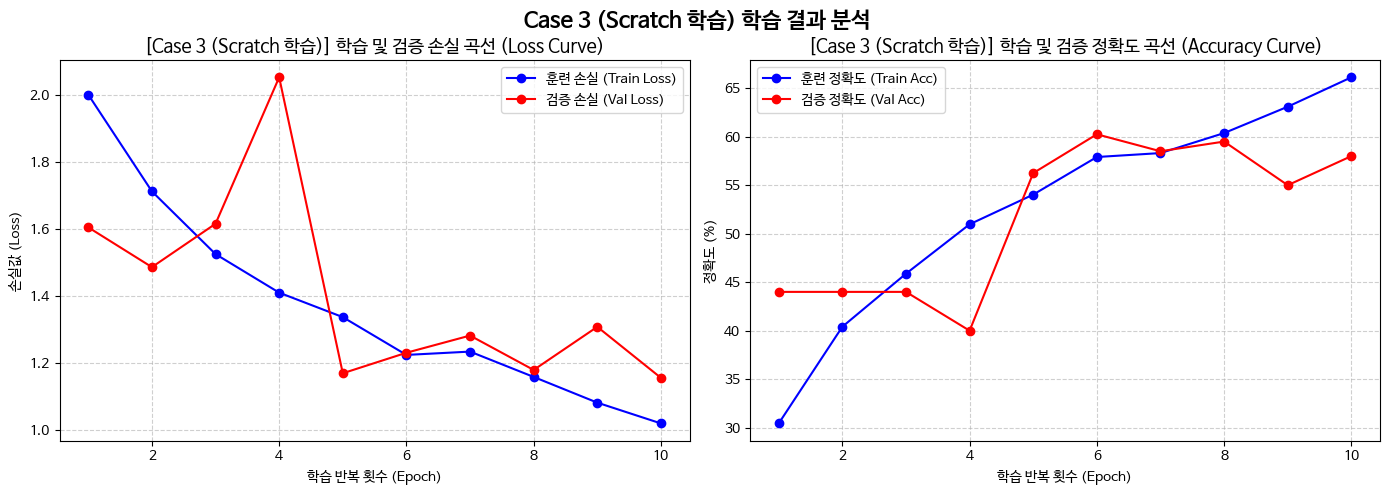

--------------------------------------------------------------------------------


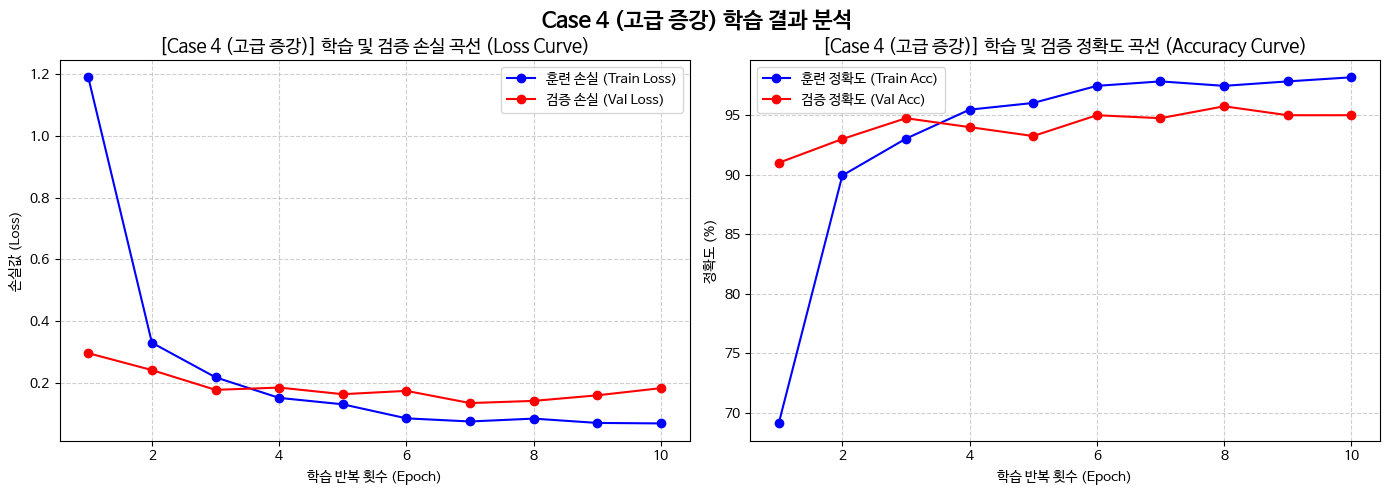

--------------------------------------------------------------------------------


In [ ]:
# [시각화] 담당: 오주희
import pickle
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# [사전 준비] 한글 폰트 깨짐 방지 세팅 (런타임 다시 시작 후 실행 필수)
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

# 1. 두 개의 피클 파일(기본 / 고급 증강) 모두 로드
with open('/content/drive/MyDrive/all_results_basic.pkl', 'rb') as f:
    basic_results = pickle.load(f)

with open('/content/drive/MyDrive/all_results_advanced.pkl', 'rb') as f:
    adv_results = pickle.load(f)

# 2. 분석할 케이스 매핑 (보고서 표에 맞게 이름과 데이터 연결)
# 💡 Case 4(고급 증강)는 advanced 파일에 저장된 Case2(미세조정)의 결과값입니다.
plot_data = {
    'Case 1 (특성 추출)': basic_results['Case1']['history'],
    'Case 2 (미세조정 - Best)': basic_results['Case2']['history'],
    'Case 3 (Scratch 학습)': basic_results['Case3']['history'],
    'Case 4 (고급 증강)': adv_results['Case2']['history']
}

# ⚠️ [참고] 만약 승태 님이 Case 5(Dropout) 피클 파일도 따로 주셨다면 아래 주석을 풀고 연결하세요!
# with open('/content/drive/MyDrive/all_results_dropout.pkl', 'rb') as f:
#     dropout_results = pickle.load(f)
# plot_data['Case 5 (고급 증강 + Dropout)'] = dropout_results['Case2']['history']

# 3. 반복문(for)을 돌면서 각 케이스별로 그래프를 하나씩 차례대로 생성
for case_name, history in plot_data.items():
    epochs = range(1, len(history['train_loss']) + 1)

    # 1행 2열 구조의 캔버스 생성 (보고서 첨부용 최적 사이즈)
    fig = plt.figure(figsize=(14, 5))
    fig.suptitle(f' {case_name} 학습 결과 분석', fontsize=16, fontweight='bold')

    # [그래프 1] 손실(Loss) 곡선
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], 'b-', label='훈련 손실 (Train Loss)', marker='o')
    plt.plot(epochs, history['val_loss'], 'r-', label='검증 손실 (Val Loss)', marker='o')
    plt.title(f'[{case_name}] 학습 및 검증 손실 곡선 (Loss Curve)', fontsize=13)
    plt.xlabel('학습 반복 횟수 (Epoch)')
    plt.ylabel('손실값 (Loss)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    # [그래프 2] 정확도(Accuracy) 곡선
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_acc'], 'b-', label='훈련 정확도 (Train Acc)', marker='o')
    plt.plot(epochs, history['val_acc'], 'r-', label='검증 정확도 (Val Acc)', marker='o')
    plt.title(f'[{case_name}] 학습 및 검증 정확도 곡선 (Accuracy Curve)', fontsize=13)
    plt.xlabel('학습 반복 횟수 (Epoch)')
    plt.ylabel('정확도 (%)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    # 간격 자동 조절 및 화면 출력
    plt.tight_layout()
    # suptitle 공간 확보를 위해 위쪽 여백 살짝 띄우기
    plt.subplots_adjust(top=0.88)
    plt.show()
    print("-" * 80) # 그래프 간 구분선 출력

📂 구글 드라이브를 연결하고 원본 데이터를 불러옵니다...
Mounted at /content/drive
✅ 테스트 데이터 400장 로드 완료!

📸 [최종 Test Set] 시각적 평가 결과 출력 중...


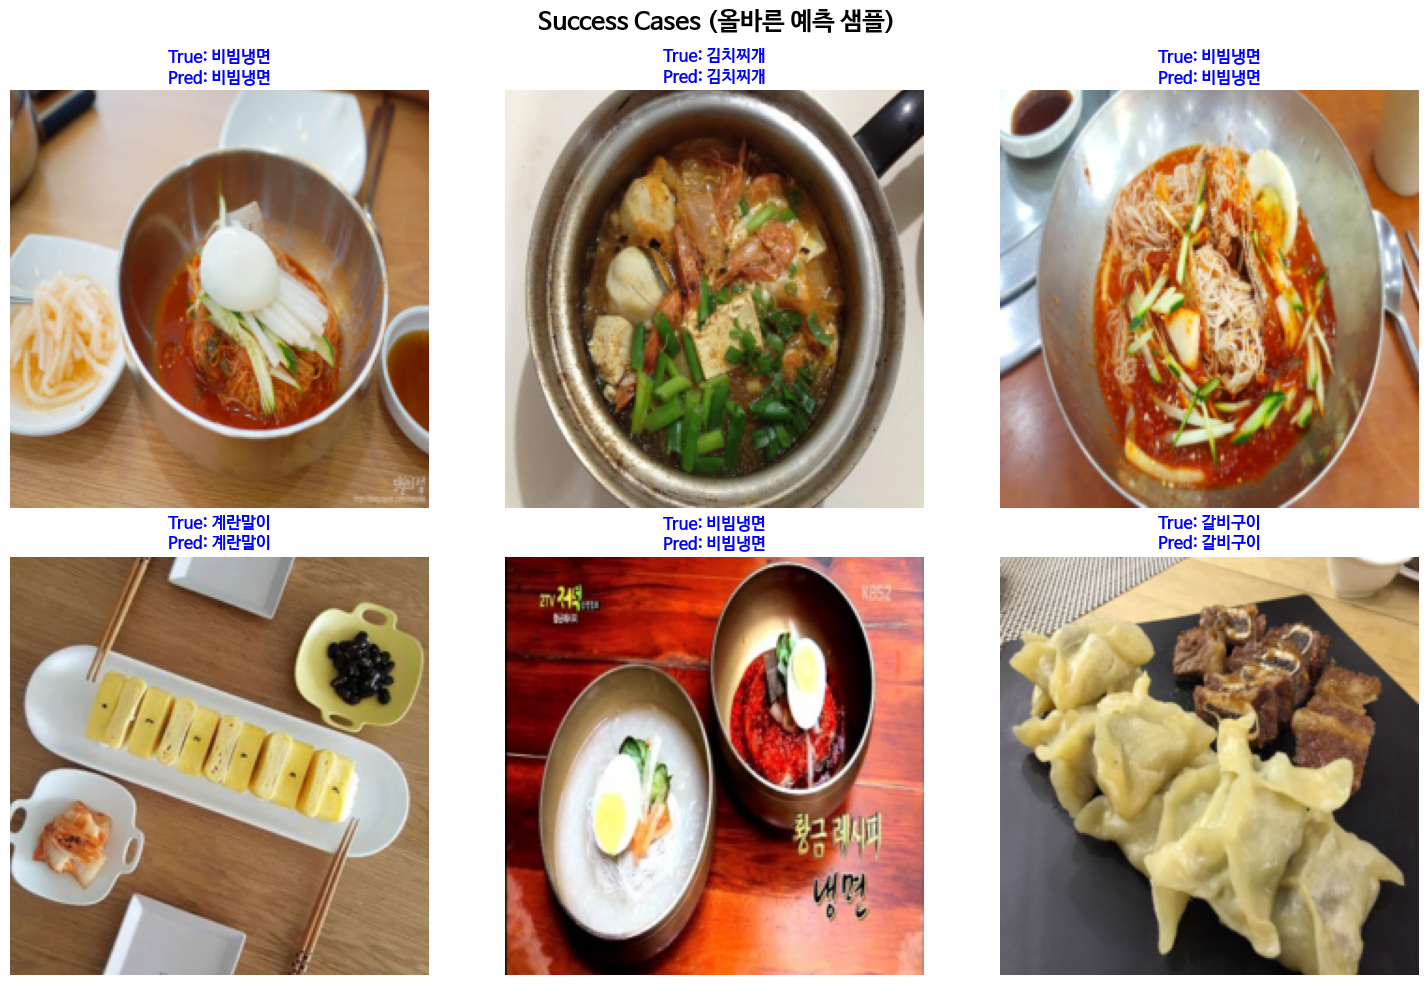

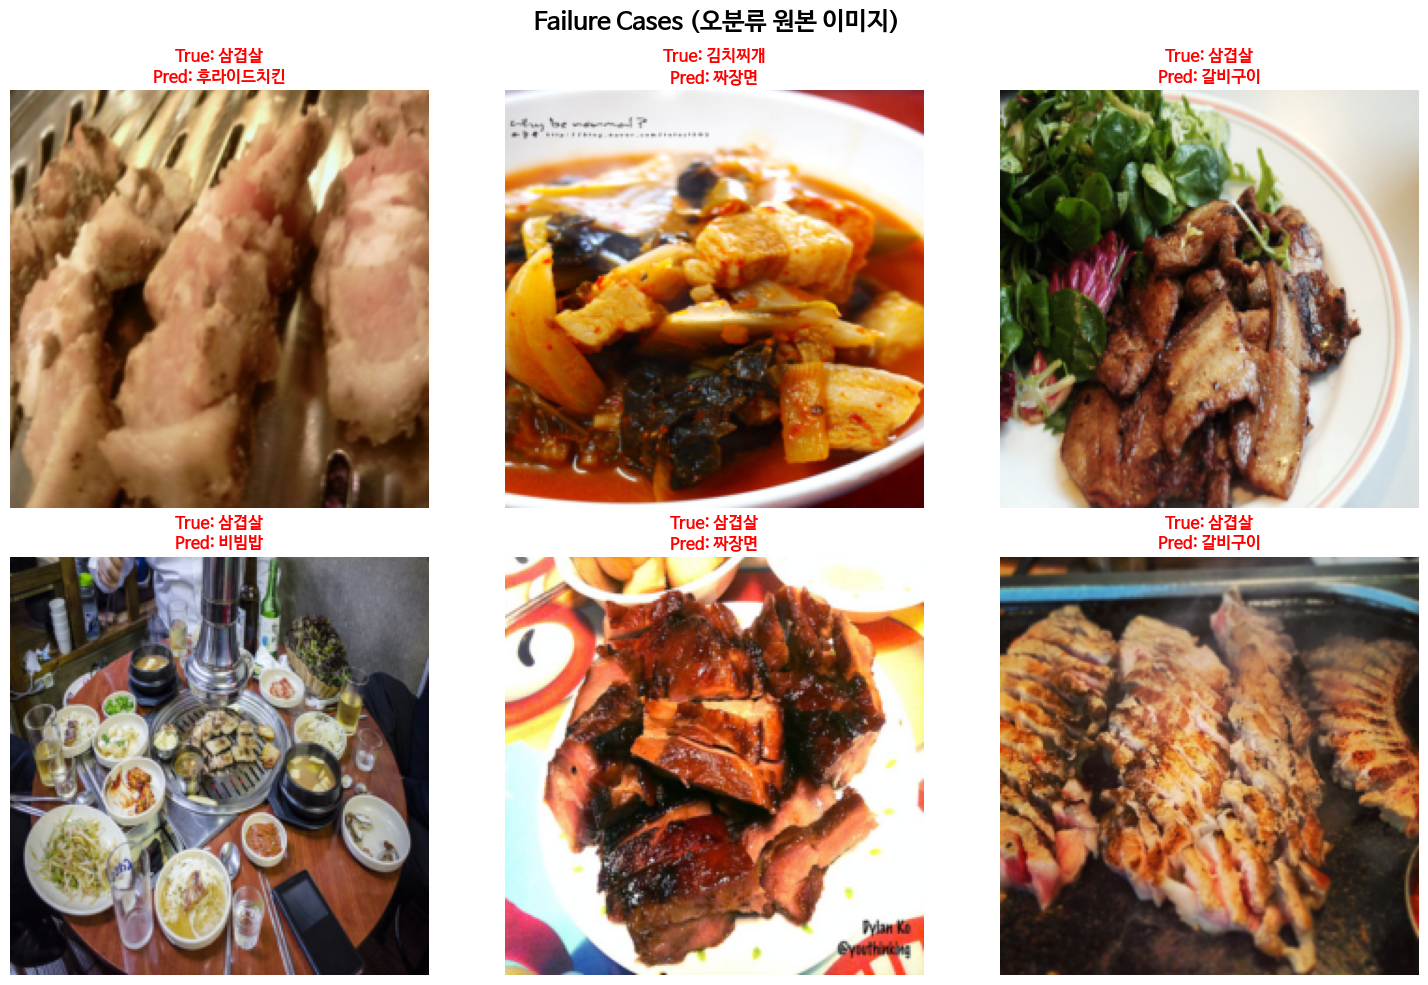

In [ ]:
# [시각화] 담당: 오주희
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from google.colab import drive
from torchvision import datasets, transforms
from torch.utils.data import Subset
from sklearn.model_selection import train_test_split

# -----------------------------------------------------------------------
# 0. 한글 폰트 강제 적용
# -----------------------------------------------------------------------
path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font_name = fm.FontProperties(fname=path, size=10).get_name()
plt.rc('font', family=font_name)
plt.rcParams['axes.unicode_minus'] = False

# -----------------------------------------------------------------------
# 1. 구글 드라이브 마운트 및 원본 이미지(test_dataset) 다시 불러오기
# -----------------------------------------------------------------------
print("📂 구글 드라이브를 연결하고 원본 데이터를 불러옵니다...")
drive.mount('/content/drive', force_remount=True)

# 데이터 전처리 규격 (기존 승태님 코드와 100% 동일하게 맞춰야 함)
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

data_dir = '/content/drive/MyDrive/KFood_Subset'
full_dataset = datasets.ImageFolder(root=data_dir)
indices = np.arange(len(full_dataset))
labels = full_dataset.targets

# 8:1:1 층화 분할 (기존과 완벽히 똑같은 인덱스를 가져오기 위해 random_state=42 유지)
train_idx, val_test_idx = train_test_split(indices, test_size=0.2, stratify=labels, random_state=42)
val_test_labels = [labels[i] for i in val_test_idx]
_, test_idx = train_test_split(val_test_idx, test_size=0.5, stratify=val_test_labels, random_state=42)

# 드디어 test_dataset 부활!
test_dataset = Subset(datasets.ImageFolder(root=data_dir, transform=val_test_transform), test_idx)
print(f"✅ 테스트 데이터 {len(test_dataset)}장 로드 완료!")

# -----------------------------------------------------------------------
# 2. 테스트 결과 피클 파일 로드 및 데이터 추출 (Case 2 기준)
# -----------------------------------------------------------------------
with open('/content/drive/MyDrive/test_results_basic.pkl', 'rb') as f:
    test_results = pickle.load(f)

preds = test_results['Case2']['test_preds']
targets = test_results['Case2']['test_targets']

class_names = ['갈비구이', '계란말이', '김밥', '김치전', '김치찌개',
               '비빔냉면', '비빔밥', '삼겹살', '짜장면', '후라이드치킨']

# 맞춘 인덱스와 틀린 인덱스 분류
success_indices = [i for i, (p, t) in enumerate(zip(preds, targets)) if p == t]
failure_indices = [i for i, (p, t) in enumerate(zip(preds, targets)) if p != t]

# -----------------------------------------------------------------------
# 3. 시각화 도우미 함수 정의
# -----------------------------------------------------------------------
def plot_samples(indices, title, is_success=True):
    num_samples = min(6, len(indices))
    if num_samples == 0:
        print(f"{title} 데이터가 없습니다.")
        return

    sample_idx = np.random.choice(indices, num_samples, replace=False)

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle(title, fontsize=18, fontweight='bold')

    for ax, idx in zip(axes.flatten(), sample_idx):
        img_tensor, true_label = test_dataset[idx]
        pred_label = preds[idx]

        # 정규화된 텐서를 시각화할 수 있도록 되돌리기 (Denormalize)
        img = img_tensor.permute(1, 2, 0).numpy()
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)

        ax.imshow(img)
        ax.axis('off')

        pred_color = 'blue' if is_success else 'red'

        ax.set_title(f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}",
                     color=pred_color, fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.subplots_adjust(top=0.9)
    plt.show()

# -----------------------------------------------------------------------
# 4. 결과 출력
# -----------------------------------------------------------------------
print("\n" + "="*70)
print("📸 [최종 Test Set] 시각적 평가 결과 출력 중...")
print("="*70)

# 1) 올바른 예측 샘플 6개 출력
plot_samples(success_indices, " Success Cases (올바른 예측 샘플)", is_success=True)

# 2) 오분류 사례 샘플 6개 출력
plot_samples(failure_indices, " Failure Cases (오분류 원본 이미지)", is_success=False)

In [ ]:
# [시각화] 담당: 오주희
import pickle
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# [1단계] 저장된 피클(.pkl) 파일 경로 설정
basic_save_path = "/content/drive/MyDrive/test_results_basic.pkl"
advanced_save_path = "/content/drive/MyDrive/test_results_advanced.pkl"

# [2단계] 결과 데이터 로드 및 병합
try:
    with open(basic_save_path, "rb") as f:
        results_basic = pickle.load(f)
    with open(advanced_save_path, "rb") as f:
        results_advanced = pickle.load(f)

    # 두 딕셔너리를 하나로 합칩니다. (Case 1, 2, 3, 4 통합)
    all_results = {**results_basic, **results_advanced}
except FileNotFoundError:
    print("저장된 결과 파일을 찾을 수 없습니다. 경로를 확인해주세요.")

# [3단계] 지표 계산 및 리스트 적재
metrics_data = []
cases = ["Case1", "Case2", "Case3", "Case4"] # 출력 순서 고정

for case in cases:
    if case in all_results:
        # 실제 정답(targets)과 모델의 예측값(preds) 추출
        targets = all_results[case]["test_targets"]
        preds = all_results[case]["test_preds"]

        # 지표 계산 (다중 분류이므로 average='macro' 적용)
        acc = accuracy_score(targets, preds)
        prec = precision_score(targets, preds, average='macro', zero_division=0)
        rec = recall_score(targets, preds, average='macro', zero_division=0)
        f1 = f1_score(targets, preds, average='macro', zero_division=0)

        # 출력 형식에 맞게 문자열 포맷팅
        metrics_data.append({
            "Case": case,
            "Accuracy": f"{acc * 100:.2f}%",
            "Precision": f"{prec:.4f}",
            "Recall": f"{rec:.4f}",
            "F1": f"{f1:.4f}"
        })

# [4단계] Pandas DataFrame 변환 및 출력
df_metrics = pd.DataFrame(metrics_data)

print("="*60)
print(" 📊 [최종 테스트 셋 평가 결과 요약표] ")
print("="*60)
# index=False 옵션을 주어 깔끔하게 표 데이터만 출력합니다.
print(df_metrics.to_string(index=False, justify='center'))
print("="*60)

 📊 [최종 테스트 셋 평가 결과 요약표] 
 Case Accuracy Precision Recall   F1  
Case1  91.50%    0.9176  0.9150 0.9150
Case2  93.50%    0.9382  0.9350 0.9338
Case3  60.50%    0.6529  0.6050 0.6060
Case4  93.25%    0.9392  0.9325 0.9315
